# Workshop-3: Machine Learning Regression Pipeline
## Course: ETL (G01) - Data Engineering & AI
### Objectives:
1. Feature engineering and strict target leakage prevention.
2. Train-test split (70% training, 30% testing).
3. Build a reproducible `scikit-learn` Pipeline combining preprocessing (imputation, scaling) and regression.
4. Model evaluation on test data (MAE, RMSE, $R^2$).
5. Serialization to `models/model.pkl` for streaming inference.


In [1]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
print('Libraries loaded successfully.')


Libraries loaded successfully.


## 1. Load Harmonized Dataset
We load `../data/processed/happiness_unified.csv` created during the data harmonization stage.


In [2]:
data_path = '../data/processed/happiness_unified.csv'
df = pd.read_csv(data_path)
print(f'Dataset Shape: {df.shape}')
df.head()


Dataset Shape: (782, 10)


,country,region,year,actual_happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,Western Europe,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,Western Europe,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,Western Europe,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,Western Europe,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,North America,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


## 2. Feature Selection & Target Leakage Prevention

### Features Selected:
- `gdp`: Economy (GDP per Capita)
- `family`: Social/family support score
- `health`: Healthy life expectancy
- `freedom`: Freedom to make life choices
- `generosity`: Generosity perception
- `corruption`: Absence of government corruption

### Features Excluded (Target Leakage):
- `Happiness Rank`: Computed directly from the target score. In production streaming, ranking is unavailable before score prediction.
- `Dystopia Residual`: Directly summed into the score formula ($Score = Factors + DystopiaResidual$).
- `Standard Error` / `Confidence Intervals`: Variances of the target measurement.


In [3]:
FEATURE_COLS = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
TARGET_COL = 'actual_happiness_score'

X = df[FEATURE_COLS]
y = df[TARGET_COL]

print('Features shape:', X.shape)
print('Target shape:', y.shape)


Features shape: (782, 6)
Target shape: (782,)


## 3. Train-Test Split (70% Train / 30% Test)
We use a fixed random seed (`random_state=42`) to guarantee experimental reproducibility.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(f'Training set size: {X_train.shape[0]} records')
print(f'Testing set size:  {X_test.shape[0]} records')


Training set size: 547 records
Testing set size:  235 records


## 4. Building the Scikit-Learn Pipeline
The pipeline bundles:
1. `SimpleImputer(strategy='median')`: Handles any potential missing numerical values at inference time.
2. `StandardScaler()`: Standardizes feature scales ($z = (x - \mu)/\sigma$).
3. `RandomForestRegressor()`: Non-linear ensemble model capturing complex interactions between economic and social factors.


In [5]:
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=4, random_state=42))
])

rf_pipeline.fit(X_train, y_train)

# Predictions
y_train_pred = rf_pipeline.predict(X_train)
y_test_pred = rf_pipeline.predict(X_test)

# Metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

metrics_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score'],
    'Train': [train_mae, train_rmse, train_r2],
    'Test': [test_mae, test_rmse, test_r2]
})
print(metrics_df.to_string(index=False))


  Metric    Train     Test
     MAE 0.171774 0.407718
    RMSE 0.224786 0.523921
R2 Score 0.960474 0.780151


## 5. Model Evaluation Visualizations


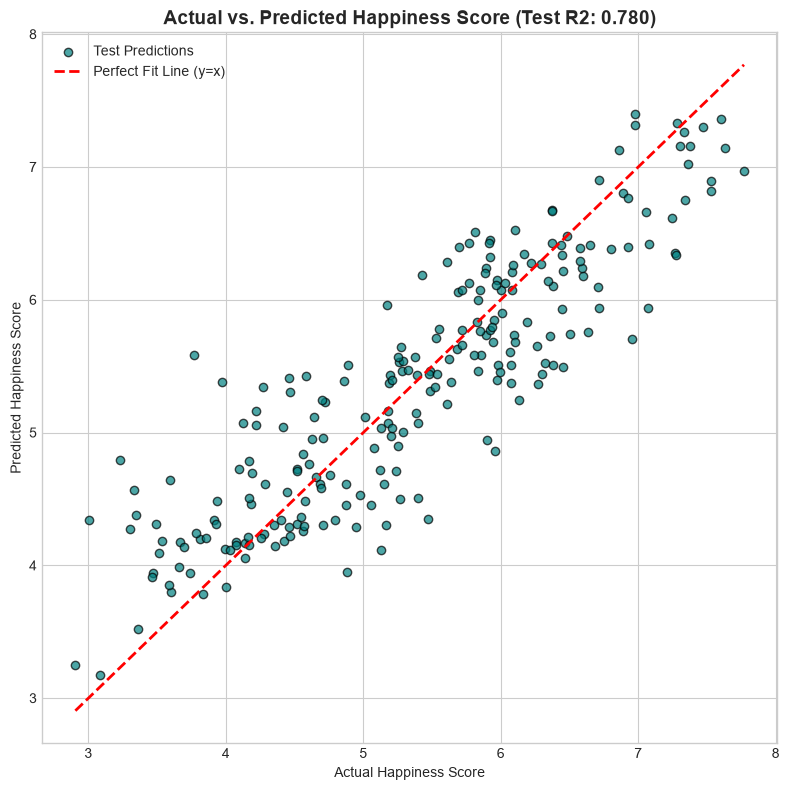

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, y_test_pred, alpha=0.7, edgecolors='k', color='teal', label='Test Predictions')
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit Line (y=x)')
ax.set_title(f'Actual vs. Predicted Happiness Score (Test R2: {test_r2:.3f})', fontsize=14, fontweight='bold')
ax.set_xlabel('Actual Happiness Score')
ax.set_ylabel('Predicted Happiness Score')
ax.legend()
plt.tight_layout()
os.makedirs('../dashboards', exist_ok=True)
plt.savefig('../dashboards/actual_vs_predicted.png', dpi=300)
plt.show()


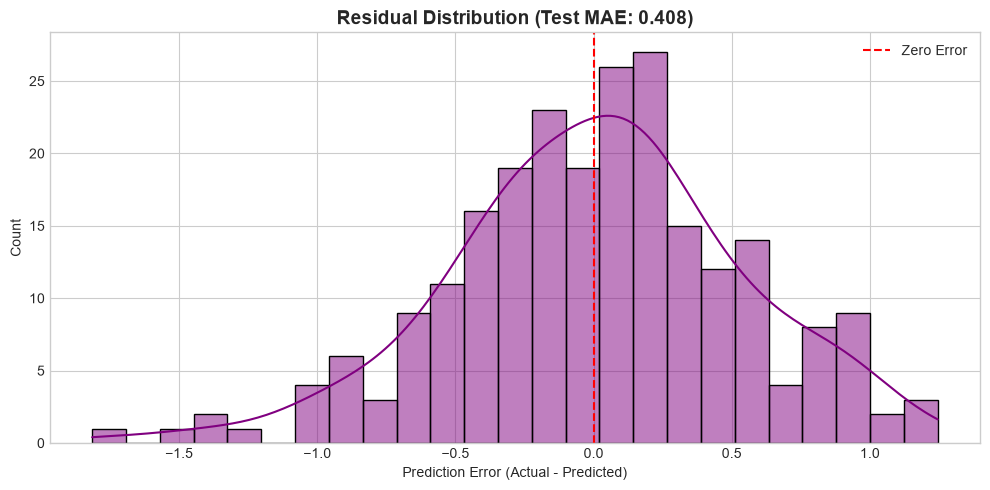

In [7]:
residuals = y_test - y_test_pred
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(residuals, kde=True, color='purple', bins=25, ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Zero Error')
ax.set_title(f'Residual Distribution (Test MAE: {test_mae:.3f})', fontsize=14, fontweight='bold')
ax.set_xlabel('Prediction Error (Actual - Predicted)')
ax.legend()
plt.tight_layout()
plt.savefig('../dashboards/residual_distribution.png', dpi=300)
plt.show()


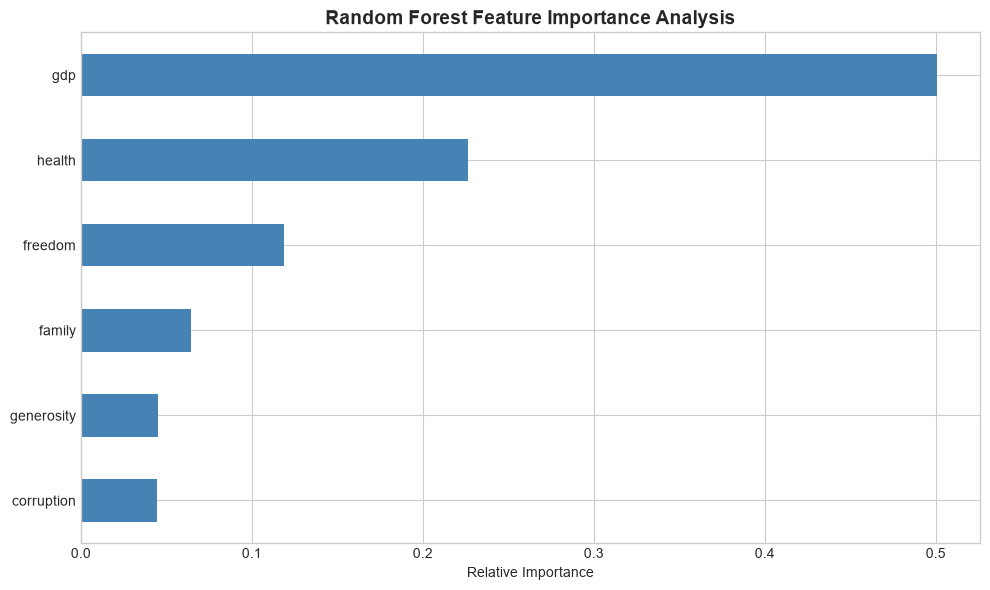

In [8]:
regressor = rf_pipeline.named_steps['regressor']
importances = regressor.feature_importances_
feat_imp = pd.Series(importances, index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', color='steelblue', ax=ax)
ax.set_title('Random Forest Feature Importance Analysis', fontsize=14, fontweight='bold')
ax.set_xlabel('Relative Importance')
plt.tight_layout()
plt.savefig('../dashboards/feature_importances.png', dpi=300)
plt.show()


## 6. Pipeline Serialization & Real-Time Inference Verification
We serialize the entire pipeline (imputer + scaler + regressor) into `../models/model.pkl`.


In [9]:
model_path = '../models/model.pkl'
os.makedirs(os.path.dirname(model_path), exist_ok=True)
joblib.dump(rf_pipeline, model_path)
print(f'Pipeline successfully serialized to: {model_path}')

# Load and test inference with sample record
loaded_pipeline = joblib.load(model_path)
sample_event = {
    'country': 'Colombia',
    'gdp': 1.2,
    'family': 0.8,
    'health': 0.9,
    'freedom': 0.6,
    'generosity': 0.3,
    'corruption': 0.1
}

input_df = pd.DataFrame([[
    sample_event['gdp'],
    sample_event['family'],
    sample_event['health'],
    sample_event['freedom'],
    sample_event['generosity'],
    sample_event['corruption']
]], columns=FEATURE_COLS)

predicted_val = loaded_pipeline.predict(input_df)[0]
print(f'Test prediction for {sample_event["country"]}: {predicted_val:.4f}')


Pipeline successfully serialized to: ../models/model.pkl
Test prediction for Colombia: 6.2399
